### Validação de Clusters: Método do Cotovelo e Silhouette Score


In [1]:
from pathlib import Path
import pandas as pd

base_path = Path.cwd().parent
file_path = base_path / "data" / "processed" / "Base_de_Dados_Treino.csv"

df = pd.read_csv(file_path, index_col="id_municipio")

df.head()

,População_2022,Pontuação Indice ODS 2025,Goal 1 Score,Goal 2 Score,Goal 3 Score,Goal 5 Score,Goal 6 Score,Goal 7 Score,Goal 8 Score,Goal 9 Score,...,Normalizado (0-100): SDG15_8_UNI_CNS,Normalizado (0-100): SDG15_PRTAMB,Normalizado (0-100): SDG16_1_OB_HM,Normalizado (0-100): SDG16_3_M_ARM_FG,Normalizado (0-100): SDG16_4_TX_HMC,Normalizado (0-100): SDG16_CRP,Normalizado (0-100): SDG16_DRTHMN,Normalizado (0-100): SDG16_TRANSP,Normalizado (0-100): SDG17_1_INVST_PB,Normalizado (0-100): SDG17_3_P_RC_TRB
id_municipio,,,,,,,,,,,,,,,,,,,,,
3918,13909.0,53.269415,59.155521,38.091787,64.289521,59.669159,64.310097,83.218333,45.514930,9.682504,...,0.000,80.0,0.0,0.0,43.239474,57.143,42.857,50.000,10.124436,13.564593
3986,21079.0,55.585523,46.276918,42.283804,69.059248,67.296407,60.647976,85.062037,55.873860,8.445009,...,0.000,80.0,100.0,0.0,75.039474,71.429,57.143,66.667,16.432705,15.811404
2758,8179.0,55.058278,50.879872,49.291735,71.076996,53.381715,60.523228,91.672593,61.346097,5.863289,...,0.021,80.0,100.0,100.0,100.000000,71.429,28.571,66.667,65.825616,21.501196
4797,2526.0,55.060949,62.635812,38.882979,72.896892,60.433893,66.063390,72.817500,58.852291,23.074656,...,0.000,80.0,100.0,100.0,100.000000,85.714,28.571,66.667,41.141996,7.627592
4504,6716.0,50.710311,46.935921,39.611815,78.407745,72.821067,60.823721,70.107870,56.257037,16.999769,...,0.000,60.0,100.0,100.0,100.000000,85.714,57.143,66.667,12.527347,10.809410


Definição do intervalo do número `k` e looping para testar melhor possibilidade de valor para a variável

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

k_range = range(2, 11)
inercia = []
silhouette_scores = []

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(X_scaled)
    
    inercia.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, cluster_labels))

Visualização, método do cotovelo e silhouette score

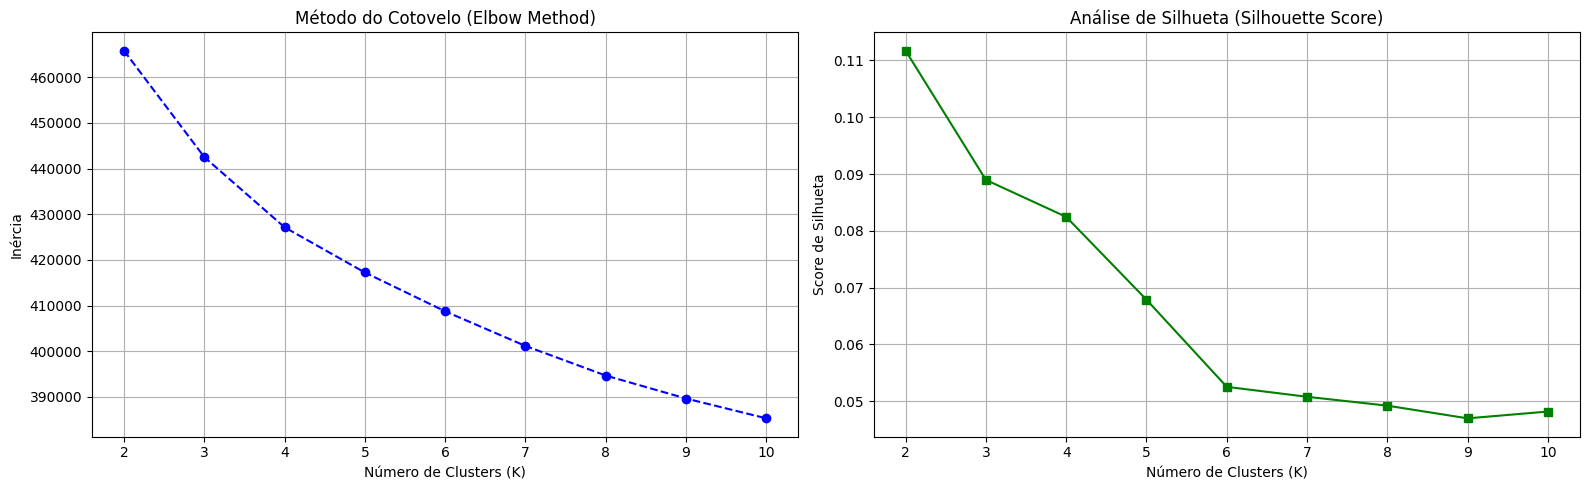

In [3]:

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

ax1.plot(k_range, inercia, marker='o', linestyle='--', color='b')
ax1.set_title('Método do Cotovelo (Elbow Method)')
ax1.set_xlabel('Número de Clusters (K)')
ax1.set_ylabel('Inércia')
ax1.grid(True)

ax2.plot(k_range, silhouette_scores, marker='s', linestyle='-', color='g')
ax2.set_title('Análise de Silhueta (Silhouette Score)')
ax2.set_xlabel('Número de Clusters (K)')
ax2.set_ylabel('Score de Silhueta')
ax2.grid(True)

plt.tight_layout()
plt.show()


### De acordo com análise de silhueta número de $k$ definido é 6

Agrupamento por perfil de município 

In [4]:
from sklearn.impute import SimpleImputer

import json

with open(base_path / "data" / "processed" / "features_perfil.json", encoding="utf-8") as f:
    features_perfil = json.load(f)

X_perfil = df[features_perfil].copy()

imputer_perfil = SimpleImputer(strategy='median')
X_perfil_imputed = pd.DataFrame(imputer_perfil.fit_transform(X_perfil), columns=features_perfil)

scaler_perfil = StandardScaler()
X_perfil_scaled = scaler_perfil.fit_transform(X_perfil_imputed)

n_perfis = 6
kmeans_perfil = KMeans(n_clusters=n_perfis, random_state=42, n_init=10)
labels_perfil = kmeans_perfil.fit_predict(X_perfil_scaled)

df['Cluster_Perfil'] = labels_perfil

Análise da média de cada variável por cluster

In [5]:
df_analise_perfis = X_perfil_imputed.copy()
df_analise_perfis['Cluster'] = labels_perfil

resumo_perfis = df_analise_perfis.groupby('Cluster').mean().round(2)
display(resumo_perfis)

,Goal 12 Score,Goal 13 Score,Goal 15 Score,Goal 2 Score,Normalizado (0-100): SDG10_21_GRV,Normalizado (0-100): SDG10_4_ACEQP,Normalizado (0-100): SDG10_DIF_FEM_NNN,Normalizado (0-100): SDG11_33_M_TRNS,Normalizado (0-100): SDG11_4_P_P_SUBN,Normalizado (0-100): SDG11_6_NGR_SUBN,...,Normalizado (0-100): SDG2_9_AGR_ORG,Normalizado (0-100): SDG3_13_SCD,Normalizado (0-100): SDG3_16_M_MAT,Normalizado (0-100): SDG3_18_T_M_NT,Normalizado (0-100): SDG5_4_P_VRDR,Normalizado (0-100): SDG5_7_JV_NENT,Normalizado (0-100): SDG6_1_IN_DRSAI,Normalizado (0-100): SDG6_8_CLT_DML,Normalizado (0-100): SDG8_2_OCP_INF,Pontuação Indice ODS 2025
Cluster,,,,,,,,,,,,,,,,,,,,,
0,68.09,70.64,25.52,43.76,60.18,99.89,99.20,67.67,99.68,0.05,...,4.78,67.26,97.31,80.74,2.78,57.48,75.37,91.78,47.25,54.47
1,75.26,51.53,23.88,47.39,49.42,99.79,97.62,56.94,99.24,0.13,...,3.43,82.60,85.80,73.98,2.67,35.12,62.48,90.21,62.15,46.35
2,69.71,66.60,23.99,46.93,58.52,99.40,1.83,66.31,97.00,0.00,...,5.33,79.61,92.79,74.08,2.22,42.19,76.31,75.65,63.88,46.01
3,60.45,70.71,33.31,47.16,64.28,65.19,69.08,77.57,54.40,0.16,...,18.27,81.97,92.96,76.42,1.74,51.23,86.71,82.32,73.15,49.14
4,78.37,72.31,17.00,48.48,58.08,99.80,99.58,70.80,99.32,0.00,...,5.69,81.46,98.17,76.86,2.66,38.24,84.83,54.26,66.76,50.23
5,75.51,66.32,20.81,46.01,52.67,99.84,88.50,64.81,98.94,0.09,...,3.39,74.82,95.17,76.14,78.32,43.21,78.13,79.06,57.03,51.15


Mapemento de perfis por nomes

In [6]:
nomes_perfis_pca = {
    0: 'Perfil 1',
    1: 'Perfil 2',
    2: 'Perfil 3',
    3: 'Perfil 4',
    4: 'Perfil 5',
    5: 'Perfil 6',
}

df['Nome_Perfil'] = df['Cluster_Perfil'].map(nomes_perfis_pca)

display(df['Nome_Perfil'].value_counts())

Nome_Perfil
Perfil 5    1289
Perfil 1    1188
Perfil 2     831
Perfil 3     606
Perfil 4     302
Perfil 6     240
Name: count, dtype: int64

#### Geração dos subconjuntos de treino por cluster (KMeans)


In [7]:
dir_saida = base_path / "data" / "processed" / "subconjuntos" / "kmeans"
dir_saida.mkdir(parents=True, exist_ok=True)

# base de treino completa (TODAS as features, não só as usadas no clustering) rotulada com o cluster
df.to_csv(dir_saida / "treino_rotulado.csv", index_label="id_municipio")

clusters_encontrados = sorted(df['Cluster_Perfil'].unique())
print(f"Clusters encontrados: {clusters_encontrados}")

for cluster_id in clusters_encontrados:
    subconjunto = df[df['Cluster_Perfil'] == cluster_id]
    nome_arquivo = f"cluster_{cluster_id}.csv"
    subconjunto.to_csv(dir_saida / nome_arquivo, index_label="id_municipio")
    print(f"  cluster {cluster_id}: {len(subconjunto)} municípios -> {dir_saida / nome_arquivo}")

print(f"\nSubconjuntos salvos em: {dir_saida}")

Clusters encontrados: [np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5)]
  cluster 0: 1188 municípios -> /home/clara/Desktop/idsc-analysis/data/processed/subconjuntos/kmeans/cluster_0.csv
  cluster 1: 831 municípios -> /home/clara/Desktop/idsc-analysis/data/processed/subconjuntos/kmeans/cluster_1.csv
  cluster 2: 606 municípios -> /home/clara/Desktop/idsc-analysis/data/processed/subconjuntos/kmeans/cluster_2.csv
  cluster 3: 302 municípios -> /home/clara/Desktop/idsc-analysis/data/processed/subconjuntos/kmeans/cluster_3.csv
  cluster 4: 1289 municípios -> /home/clara/Desktop/idsc-analysis/data/processed/subconjuntos/kmeans/cluster_4.csv
  cluster 5: 240 municípios -> /home/clara/Desktop/idsc-analysis/data/processed/subconjuntos/kmeans/cluster_5.csv

Subconjuntos salvos em: /home/clara/Desktop/idsc-analysis/data/processed/subconjuntos/kmeans
